In [8]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [14]:
train = pd.read_csv("../data/cs-training.csv", index_col=0)
test=pd.read_csv("../data/cs-test.csv", index_col=0)

print(train.shape)
print(test.shape)

train.head()

(150000, 12)
(101503, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [16]:
train.info() # this is used as dataset information

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

In [18]:
train.isnull().sum() # this is usefull to see missing values

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [48]:
train.describe() # used as descrptive statistics

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalPayments,TotalLoans
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413,0.927393,9.471000
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021,12.466204,5.727394
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000,9.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,0.000000,13.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000,294.000000,112.000000


In [50]:
print("Duplicates:",train.duplicated().sum())
train=train.drop_duplicates()

Duplicates: 0


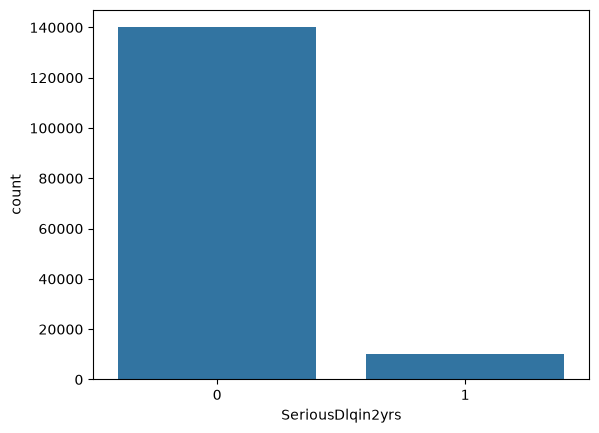

In [52]:
#target analysis
train["SeriousDlqin2yrs"].value_counts()

sns.countplot(
    x="SeriousDlqin2yrs",
    data=train
)

plt.show()

In [53]:
#now let's start with data cleaning
train["MonthlyIncome"]=train["MonthlyIncome"].fillna(
    train["MonthlyIncome"].median()
)

train["NumberOfDependents"]=train["NumberOfDependents"].fillna(
    train["NumberOfDependents"].median()
)

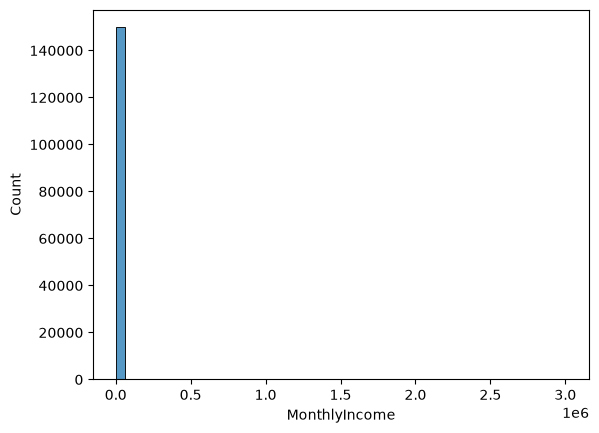

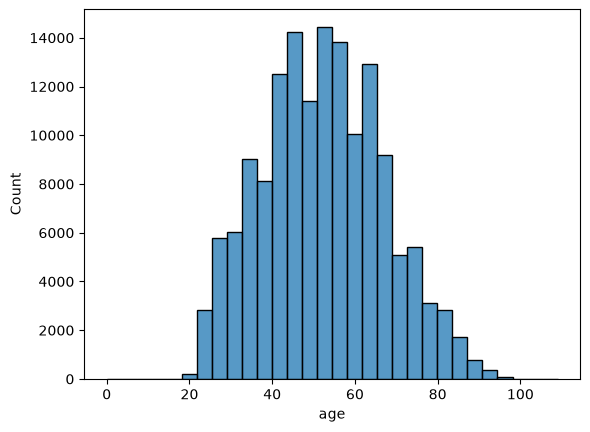

In [54]:
sns.histplot(
    train["MonthlyIncome"],
    bins=50
)

plt.show()

sns.histplot(
    train["age"],
    bins=30
)

plt.show()

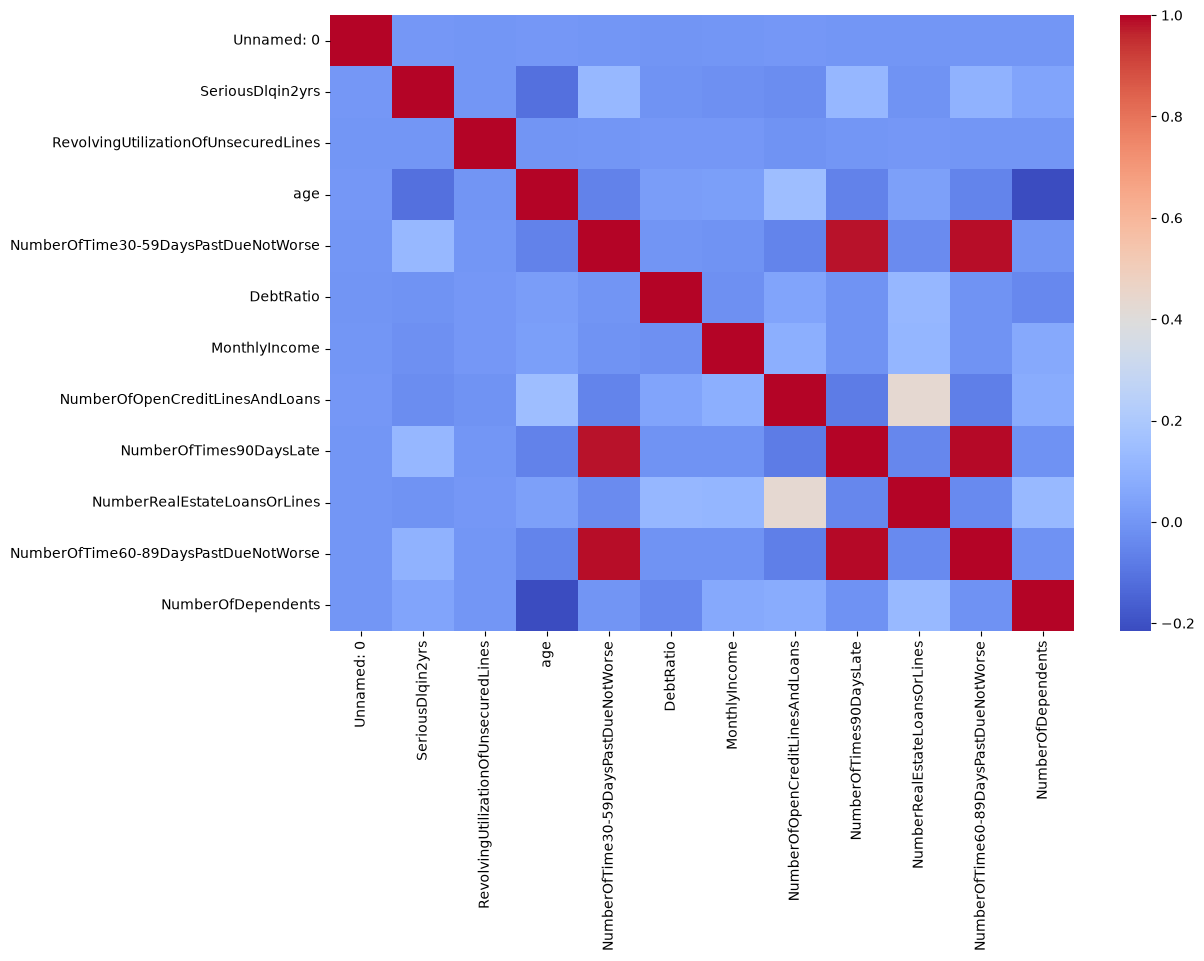

In [27]:
plt.figure(figsize=(12,8))

sns.heatmap(
    train.corr(),
    cmap="coolwarm"
)

plt.show()

In [57]:
late_cols = [
'NumberOfTime30-59DaysPastDueNotWorse',
'NumberOfTime60-89DaysPastDueNotWorse',
'NumberOfTimes90DaysLate'
]
for col in late_cols:
    print(col)
    print(train[col].value_counts().head(20))

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0     126018
1      16033
2       4598
3       1754
4        747
5        342
98       264
6        140
7         54
8         25
9         12
96         5
10         4
12         2
13         1
11         1
Name: count, dtype: int64
NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     142396
1       5731
2       1118
3        318
98       264
4        105
5         34
6         16
7          9
96         5
8          2
11         1
9          1
Name: count, dtype: int64
NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
98       264
5        131
6         80
7         38
8         21
9         19
10         8
96         5
11         5
13         4
15         2
14         2
12         2
17         1
Name: count, dtype: int64


In [58]:
train["TotalPayments"]=(
    train["NumberOfTime30-59DaysPastDueNotWorse"]+
    train["NumberOfTime60-89DaysPastDueNotWorse"]+
    train["NumberOfTimes90DaysLate"]
)

train["TotalLoans"] =(
    train["NumberOfOpenCreditLinesAndLoans"]+
    train["NumberRealEstateLoansOrLines"]
)

In [59]:
#now we are doing the train/ test.split
y=train["SeriousDlqin2yrs"]
X=train.drop(
    "SeriousDlqin2yrs",
    axis=1
)

X_train,X_valid,y_train,y_valid=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

In [33]:
#Logistic Regression

lr=LogisticRegression(max_iter=1000)

lr.fit(
    X_train,
    y_train
)

pred_lr=lr.predict(X_valid)

C:\Users\User\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [35]:
#now with decision tree
dt=DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)
pred_dt=dt.predict(X_valid)

In [39]:
rf=RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(
    X_train,y_train
)
pred_rf=rf.predict(X_valid)

In [61]:
# now we are going to do a model evaluation

def evaluate(y_true,pred):
    print(
        "Accuracy",
        accuracy_score(y_true,pred)
    )
    print(
        "Precision:",
        precision_score(y_true,pred)
    )
    print(
        "Recall:",
        recall_score(y_true,pred)
    )
    print(
        "F1:",
        f1_score(y_true,pred)
    )
    print(
        "confusion_matrix:",
        confusion_matrix(y_true,pred)
    )

In [62]:
evaluate(y_valid,pred_lr)
evaluate(y_valid,pred_dt)
evaluate(y_valid,pred_rf)

Accuracy 0.9332333333333334
Precision: 0.509090909090909
Recall: 0.027930174563591023
F1: 0.052955082742316785
confusion_matrix: [[27941    54]
 [ 1949    56]]
Accuracy 0.8976
Precision: 0.2578302315024966
Recall: 0.2832917705735661
F1: 0.26996197718631176
confusion_matrix: [[26360  1635]
 [ 1437   568]]
Accuracy 0.9363
Precision: 0.5743670886075949
Recall: 0.18104738154613467
F1: 0.2753128555176337
confusion_matrix: [[27726   269]
 [ 1642   363]]


In [46]:
rf_prob=rf.predict_proba(
    X_valid
)[:,1]

roc_auc_score(
    y_valid,
    rf_prob
)

0.8508498979377775

In [47]:
importance =pd.DataFrame({
    "Feature":X.columns,
    "Importance":rf.feature_importances_
})

importance.sort_values(
by="Importance",
ascending=False
)

,Feature,Importance
1,RevolvingUtilizationOfUnsecuredLines,0.148780
0,Unnamed: 0,0.136109
4,DebtRatio,0.131100
5,MonthlyIncome,0.111490
2,age,0.102360
11,TotalPayments,0.078972
7,NumberOfTimes90DaysLate,0.060568
12,TotalLoans,0.056524
6,NumberOfOpenCreditLinesAndLoans,0.055909
10,NumberOfDependents,0.035622
